# Carga de archivos

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../datos/data.csv")

# Item 2: Manejo de datos faltantes

In [36]:
missing_df = pd.DataFrame({
    'Valores Nulos': df.isnull().sum(),
    'Porcentaje (%)': (df.isnull().sum() / len(df)) * 100
})


print(missing_df[missing_df['Valores Nulos'] > 0].sort_values(by='Porcentaje (%)', ascending=False))

                  Valores Nulos  Porcentaje (%)
Market Category            3742       31.408427
Engine HP                    69        0.579151
Engine Cylinders             30        0.251805
Number of Doors               6        0.050361
Engine Fuel Type              3        0.025180


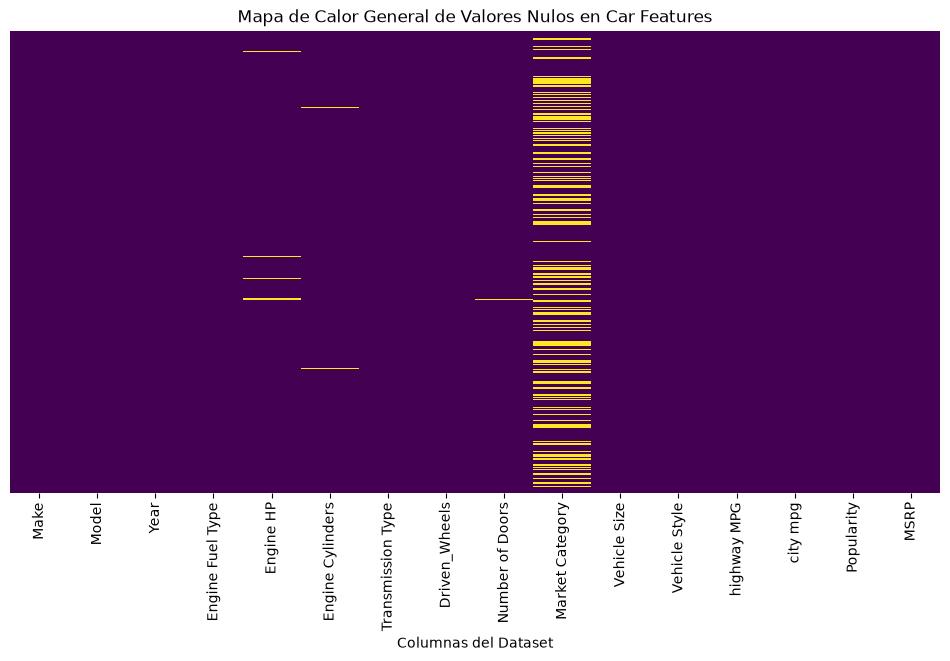

In [37]:
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Mapa de Calor General de Valores Nulos en Car Features')
plt.xlabel('Columnas del Dataset')
plt.show()

In [38]:
if 'Engine HP' in df.columns:
    mediana_hp = df['Engine HP'].median()
    df['Engine HP'] = df['Engine HP'].fillna(mediana_hp)


if 'Engine Cylinders' in df.columns:
    moda_cilindros = df['Engine Cylinders'].mode()[0]
    df['Engine Cylinders'] = df['Engine Cylinders'].fillna(moda_cilindros)

df.loc[:,['Engine HP','Engine Cylinders']]

,Engine HP,Engine Cylinders
0,335.0,6.0
1,300.0,6.0
2,300.0,6.0
3,230.0,6.0
4,230.0,6.0
...,...,...
11909,300.0,6.0
11910,300.0,6.0
11911,300.0,6.0
11912,300.0,6.0


In [39]:
if 'MSRP' in df.columns:
    filas_iniciales = len(df)
    df.dropna(subset=['MSRP'], inplace=True)

df['MSRP']

/tmp/ipykernel_12902/606349789.py:3: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['MSRP'], inplace=True)


0        46135
1        40650
2        36350
3        29450
4        34500
         ...  
11909    46120
11910    56670
11911    50620
11912    50920
11913    28995
Name: MSRP, Length: 11914, dtype: int64

# Item 4: 	Valores inconsistentes y duplicados

In [40]:
duplicados_totales = df.duplicated().sum()
print(f"Número de filas duplicadas encontradas: {duplicados_totales}")

Número de filas duplicadas encontradas: 715


In [41]:
df = df.drop_duplicates().reset_index(drop=True)

In [42]:
columnas_texto = df.select_dtypes(include=['object']).columns

for col in columnas_texto:
   
    df[col] = df[col].astype(str).str.strip().str.title()
    
    
    df[col] = df[col].replace(['Nan', 'None', 'Na'], np.nan)

/tmp/ipykernel_12902/1270027836.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_texto = df.select_dtypes(include=['object']).columns


In [43]:
print("Valores únicos antes de corregir en Transmission Type:")
print(df['Transmission Type'].value_counts())

Valores únicos antes de corregir en Transmission Type:
Transmission Type
Automatic           7932
Manual              2634
Automated_Manual     553
Direct_Drive          68
Unknown               12
Name: count, dtype: int64


# Item 6: 	Filtrado y condiciones en pandas

In [44]:
top_marcas = df.groupby('Make')['MSRP'].mean().sort_values(ascending=False).head(5)
print(f"Marcas más caras en promedio:  {top_marcas.round(2)}")

Marcas más caras en promedio:  Make
Bugatti        1757223.67
Maybach         546221.88
Rolls-Royce     351130.65
Lamborghini     331567.31
Bentley         247169.32
Name: MSRP, dtype: float64


In [54]:
ultra_hp = df[df['Engine HP'] > 500]
print(f"Cantidad de autos con más de 500 HP: {len(ultra_hp)}")
print(ultra_hp[['Make', 'Model', 'Engine HP', 'MSRP']])

Cantidad de autos con más de 500 HP: 485
          Make       Model  Engine HP    MSRP
447    Ferrari  458 Italia      562.0  257412
448    Ferrari  458 Italia      562.0  233509
449    Ferrari  458 Italia      562.0  233509
450    Ferrari  458 Italia      597.0  288000
451    Ferrari  458 Italia      562.0  257412
...        ...         ...        ...     ...
10798      Bmw        X5 M      567.0   98800
10799      Bmw        X5 M      567.0   98800
10812      Bmw        X6 M      567.0  102100
10813      Bmw        X6 M      567.0  102200
10814      Bmw        X6 M      567.0  102200

[485 rows x 4 columns]


In [53]:
electricos = df[df['Engine Cylinders'] == 0]
print(f" Total de vehículos con 0 cilindros: {len(electricos)}")
if len(electricos) > 0:
    print(electricos[['Make', 'Model', 'MSRP']])

 Total de vehículos con 0 cilindros: 56
               Make                   Model    MSRP
520            Fiat                    500E   31800
521            Fiat                    500E   31800
522            Fiat                    500E   31800
1642  Mercedes-Benz  B-Class Electric Drive   41450
1643  Mercedes-Benz  B-Class Electric Drive   41450
1644  Mercedes-Benz  B-Class Electric Drive   39900
4470          Honda                  Fit Ev   36625
4471          Honda                  Fit Ev   36625
4550           Ford                   Focus   29170
4554           Ford                   Focus   29170
4563           Ford                   Focus   29120
5505            Bmw                      I3   42400
5506            Bmw                      I3   42400
5507            Bmw                      I3   42400
5508            Bmw                      I3   43600
6035         Nissan                    Leaf   35020
6036         Nissan                    Leaf   32000
6037         Nissan     

In [52]:
familiares_accesibles = df[(df['Number of Doors'] == 4) & (df['Year'] >= 2015) & (df['MSRP'] < 25000)]
print(f"Cantidad de autos familiares modernos y accesibles: {len(familiares_accesibles)}")
print(familiares_accesibles[['Make', 'Model', 'Year', 'MSRP']])

Cantidad de autos familiares modernos y accesibles: 945
           Make  Model  Year   MSRP
60     Chrysler    200  2015  23950
62     Chrysler    200  2015  21995
65     Chrysler    200  2016  21995
69     Chrysler    200  2016  22490
72     Chrysler    200  2016  24490
...         ...    ...   ...    ...
11109    Toyota  Yaris  2016  15995
11113    Toyota  Yaris  2017  16375
11114    Toyota  Yaris  2017  17285
11115    Toyota  Yaris  2017  18000
11116    Toyota  Yaris  2017  17200

[945 rows x 4 columns]


In [55]:
deportivos_accesibles = df[(df['Number of Doors'] == 2) & (df['MSRP'] < 25000)]
print(f"Cantidad de autos deportivos de 2 puertas por menos de $25,000: {len(deportivos_accesibles)}")
print(deportivos_accesibles[['Make', 'Model', 'Year', 'MSRP']])

Cantidad de autos deportivos de 2 puertas por menos de $25,000: 1188
         Make       Model  Year   MSRP
28       Fiat  124 Spider  2017  24995
82     Nissan       200Sx  1996   2000
83     Nissan       200Sx  1996   2000
84     Nissan       200Sx  1997   2000
85     Nissan       200Sx  1997   2000
...       ...         ...   ...    ...
11111  Toyota       Yaris  2017  16910
11112  Toyota       Yaris  2017  15250
11166     Bmw          Z3  2000   4976
11167     Bmw          Z3  2000   4697
11168     Bmw          Z3  2000   4755

[1188 rows x 4 columns]
